In [24]:
import io
import pathlib
import urllib.request
import zipfile

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import fetch_california_housing

import torch
from torch import nn, optim

torch.manual_seed(1234)
np.random.seed(1234)

In [25]:
dados = fetch_california_housing(as_frame=True)

### 1. Uma breve análise dos dados: o que cada variável significa, describe() e um gráfico de dispersão de pelo menos duas variáveis contra o preço.

In [26]:
df = dados.frame
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [27]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


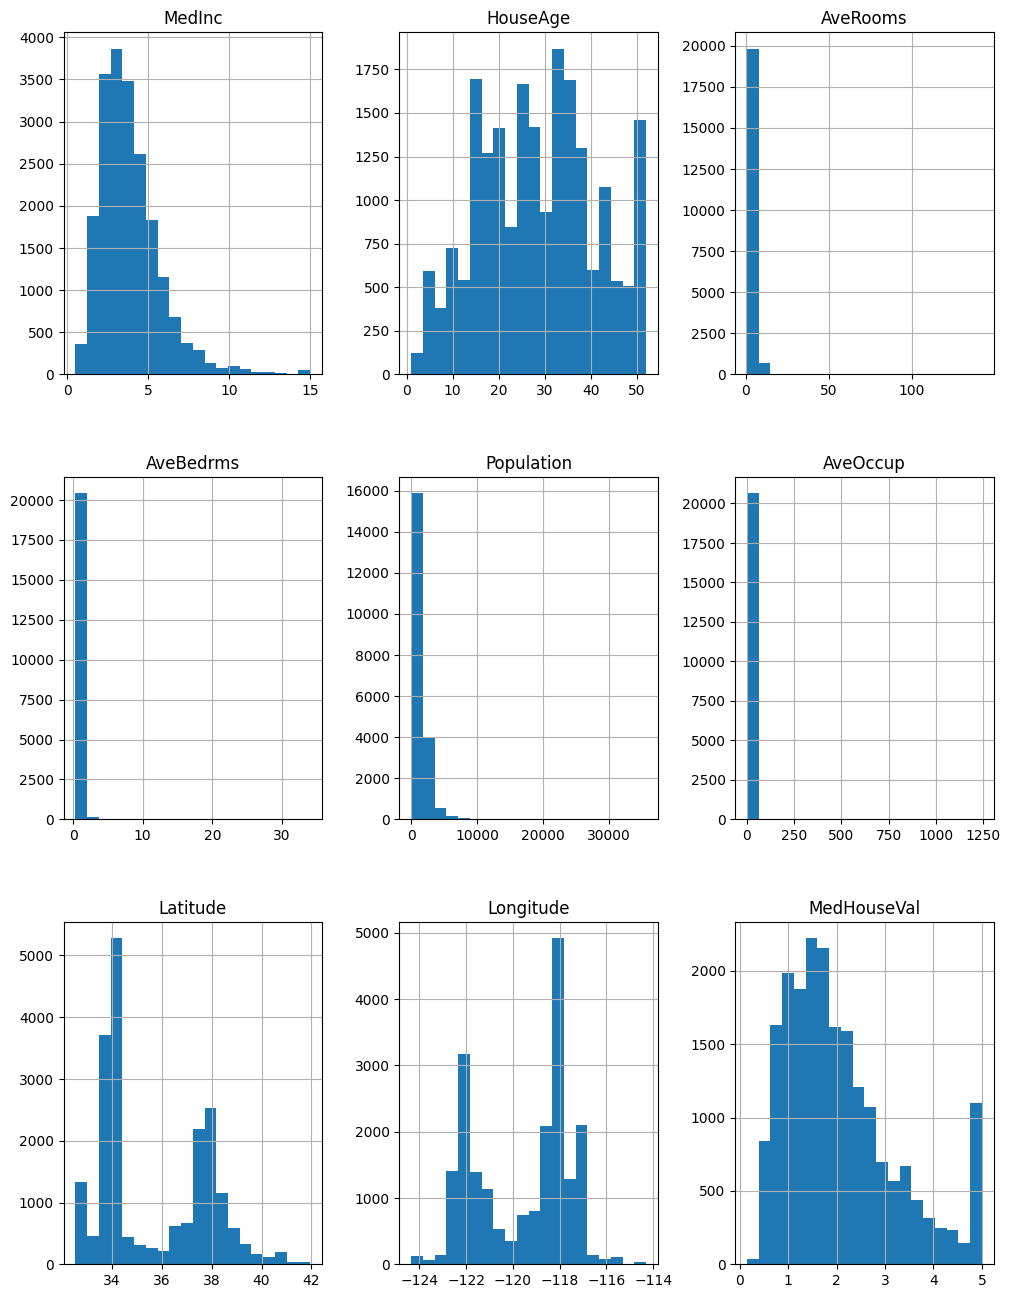

In [28]:
df.hist(figsize=(12, 16), bins=20)
plt.show()

,0
MedInc,"Axes(0.125,0.653529;0.227941x0.226471)"
HouseAge,"Axes(0.398529,0.653529;0.227941x0.226471)"
AveRooms,"Axes(0.672059,0.653529;0.227941x0.226471)"
AveBedrms,"Axes(0.125,0.381765;0.227941x0.226471)"
Population,"Axes(0.398529,0.381765;0.227941x0.226471)"
AveOccup,"Axes(0.672059,0.381765;0.227941x0.226471)"
Latitude,"Axes(0.125,0.11;0.227941x0.226471)"
Longitude,"Axes(0.398529,0.11;0.227941x0.226471)"
MedHouseVal,"Axes(0.672059,0.11;0.227941x0.226471)"


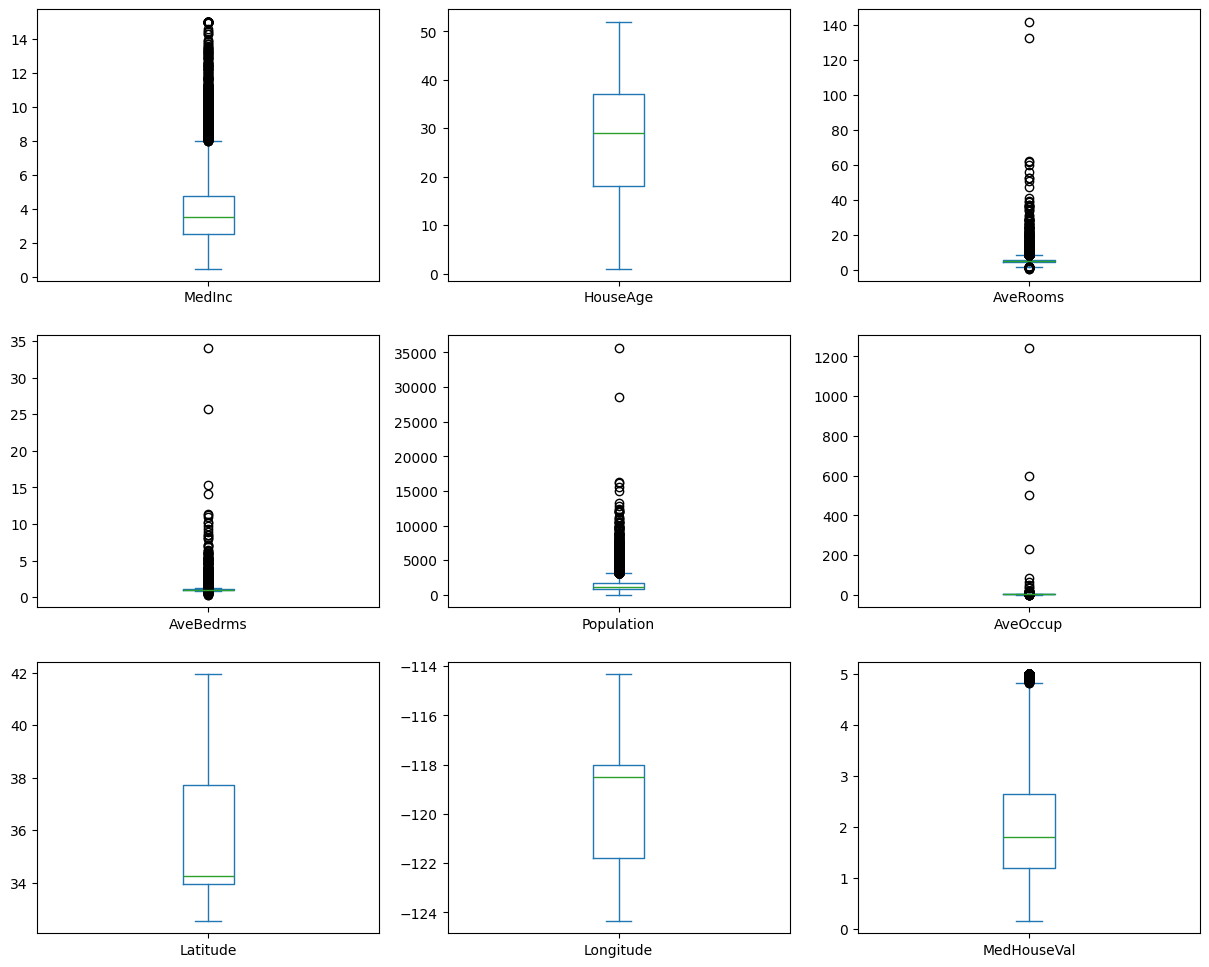

In [29]:
df.plot(
    kind='box',
    subplots=True,
    layout=(3,3),
    figsize=(15,12),
    sharex=False,
    sharey=False
)

<Axes: >

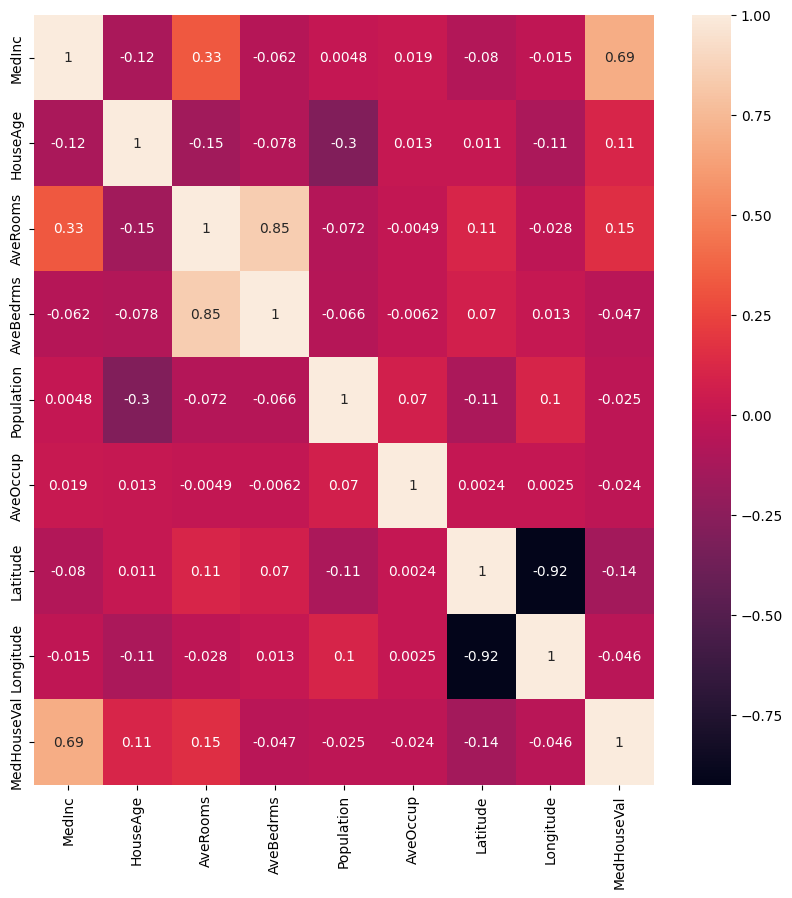

In [30]:
corr = df.corr()

plt.figure(figsize=(10, 10))
sns.heatmap(corr, annot=True)

Text(0.5, 1.0, 'AveRooms x MedHouseVal')

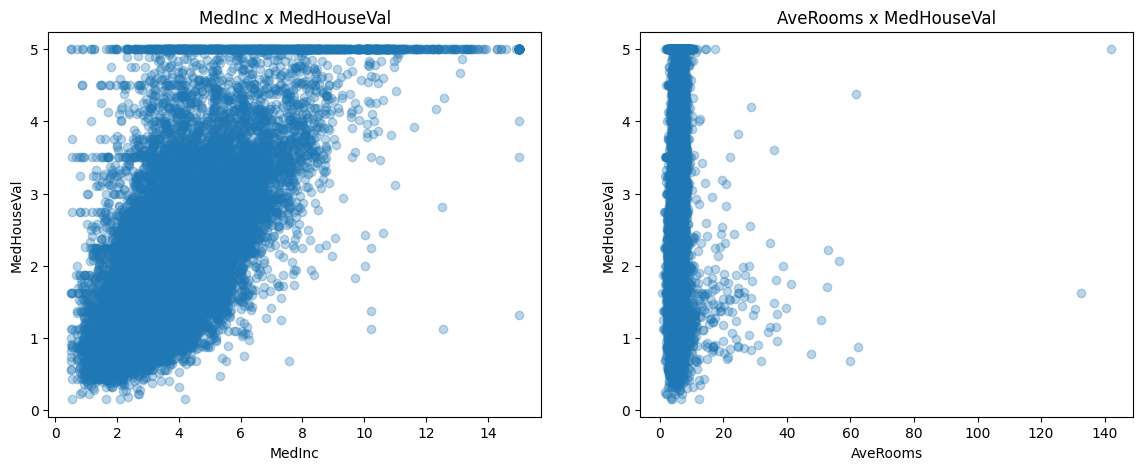

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(df['MedInc'], df['MedHouseVal'], alpha=0.3)
axes[0].set_xlabel('MedInc')
axes[0].set_ylabel('MedHouseVal')
axes[0].set_title('MedInc x MedHouseVal')

axes[1].scatter(df['AveRooms'], df['MedHouseVal'], alpha=0.3)
axes[1].set_xlabel('AveRooms')
axes[1].set_ylabel('MedHouseVal')
axes[1].set_title('AveRooms x MedHouseVal')

MedInc: Renda mediana no quarteirão (em dezenas de milhares de dólares, ex: 3.87 = US$ 38.700). É a variável com maior correlação positiva com o preço (0.69).

HouseAge: Idade mediana das casas no quarteirão (em anos).

AveRooms: Número médio de cômodos por domicílio.

AveBedrms: Número médio de quartos (dormitórios) por domicílio.

Population: População total do quarteirão.

AveOccup: Número médio de moradores por domicílio.

Latitude / Longitude: Coordenadas geográficas do quarteirão.

MedHouseVal (Alvo): Valor mediano das casas no quarteirão (em centenas de milhares de dólares, ex: 2.06 = US$ 206.000).

### 2. Divisão em treino, validação e teste (por exemplo 70/15/15, com random_state fixo).

In [32]:
# Separando features (X) e alvo (y)
X = df.drop(columns=['MedHouseVal']).values
y = df[['MedHouseVal']].values  # Formato 2D (N, 1) exigido pelo StandardScaler e nn.Linear

# Divisão: 70% treino e 30% (validação + teste)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=1234
)

# Divisão do teste em 50%/50% (resultando em 15% validação e 15% teste)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=1234
)

### 3. Padronização das entradas e da saída com StandardScaler ajustado só no treino.

In [33]:
# Padronização
scaler_X = StandardScaler()
X_train_scaled = scaler_X.fit_transform(X_train)
X_val_scaled = scaler_X.transform(X_val)
X_test_scaled = scaler_X.transform(X_test)

scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(y_train)
y_val_scaled = scaler_y.transform(y_val)
y_test_scaled = scaler_y.transform(y_test)

In [34]:
# Convertendo para tensores do PyTorch
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train_scaled, dtype=torch.float32)

X_val_t = torch.tensor(X_val_scaled, dtype=torch.float32)
y_val_t = torch.tensor(y_val_scaled, dtype=torch.float32)

X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_t = torch.tensor(y_test_scaled, dtype=torch.float32)

### 4. Treinamento com nn.Linear(8, 1), nn.MSELoss e optim.SGD, com as curvas de custo de treino e de validação.

In [35]:
torch.manual_seed(1234)
model = nn.Linear(8, 1)
print('weights (w1..w8):', model.weight)
print('bias (w0):       ', model.bias)

lr = 0.05
criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=lr)

weights (w1..w8): Parameter containing:
tensor([[-0.3331, -0.0694, -0.1698, -0.0943, -0.3123,  0.1419, -0.3169, -0.0225]],
       requires_grad=True)
bias (w0):        Parameter containing:
tensor([0.1229], requires_grad=True)


In [36]:
def train_epoch(model, optimizer, criterion, x_train, y_train):
    model.train()            # modo de treino
    optimizer.zero_grad()

    # forward
    y_pred = model(x_train)
    loss = criterion(y_pred, y_train)

    # backward e otimizador
    loss.backward()
    optimizer.step()

    return loss.item()       # custo como número Python

In [37]:
def validate_epoch(model, criterion, x_val, y_val):
    model.eval()             # modo de avaliação
    with torch.no_grad():    # sem grafo do autograd: não haverá backward
        y_pred = model(x_val)
        loss = criterion(y_pred, y_val)
    return loss.item()

In [38]:
n_epochs = 200
train_losses = []
val_losses = []

for epoch in range(n_epochs):
    train_loss = train_epoch(model, optimizer, criterion, X_train_t, y_train_t)
    train_losses.append(train_loss)

    val_loss = validate_epoch(model, criterion, X_val_t, y_val_t)
    val_losses.append(val_loss)

    if (epoch + 1) % 20 == 0:
        print(f'Epoch[{epoch + 1}/{n_epochs}], Train Loss: {train_loss:.6f}, Val Loss: {val_loss:.6f}')

Epoch[20/200], Train Loss: 0.477908, Val Loss: 0.475378
Epoch[40/200], Train Loss: 0.432596, Val Loss: 0.432379
Epoch[60/200], Train Loss: 0.419537, Val Loss: 0.419367
Epoch[80/200], Train Loss: 0.411307, Val Loss: 0.411908
Epoch[100/200], Train Loss: 0.405646, Val Loss: 0.407334
Epoch[120/200], Train Loss: 0.401711, Val Loss: 0.404595
Epoch[140/200], Train Loss: 0.398967, Val Loss: 0.403042
Epoch[160/200], Train Loss: 0.397046, Val Loss: 0.402244
Epoch[180/200], Train Loss: 0.395696, Val Loss: 0.401915
Epoch[200/200], Train Loss: 0.394743, Val Loss: 0.401866


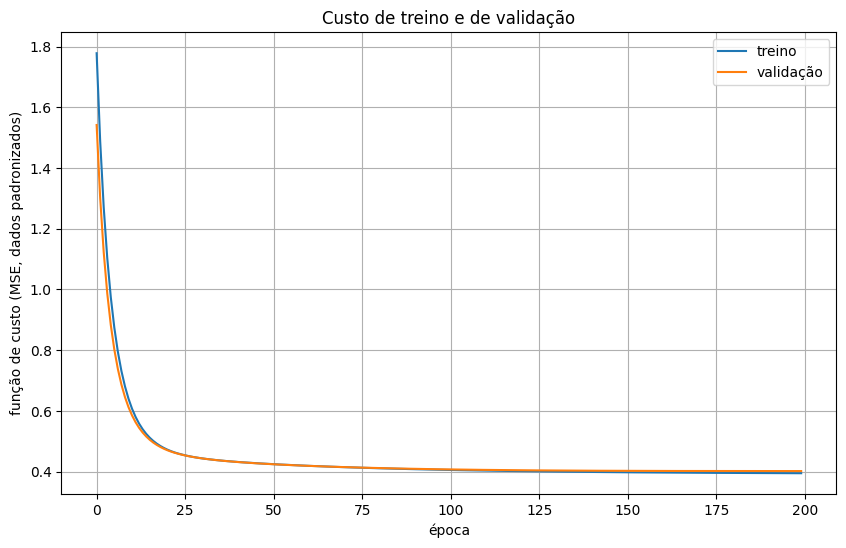

In [39]:
plt.figure(figsize=(10, 6))
plt.plot(range(n_epochs), train_losses, label='treino')
plt.plot(range(n_epochs), val_losses, label='validação')
plt.xlabel('época')
plt.ylabel('função de custo (MSE, dados padronizados)')
plt.title('Custo de treino e de validação')
plt.legend()
plt.grid(True)
plt.show()

### 5. RMSE no teste em dólares, comparado com um baseline que sempre prevê o preço médio do treino.

In [40]:
model.eval()
with torch.no_grad():
    y_test_pred = model(X_test_t)

# Reverte a padronização
y_test_pred_raw = scaler_y.inverse_transform(y_test_pred.numpy())

# Multiplica por 100.000 para obter os valores em dólares
y_test_pred_dolares = y_test_pred_raw * 100_000
y_test_dolares = y_test * 100_000

# Cálculo do RMSE
rmse_test = torch.sqrt(
    criterion(torch.from_numpy(y_test_pred_dolares), torch.from_numpy(y_test_dolares))
).item()

# Calcula o Baseline
media_treino_dolares = np.full_like(y_test_dolares, y_train.mean() * 100_000)
rmse_baseline = torch.sqrt(
    criterion(torch.from_numpy(media_treino_dolares), torch.from_numpy(y_test_dolares))
).item()

print(f'Preço médio no treino:           US$ {y_train.mean() * 100_000:,.2f}')
print(f'RMSE Baseline (Média do Treino): US$ {rmse_baseline:,.2f}')
print(f'RMSE do Modelo no Teste:         US$ {rmse_test:,.2f}')

Preço médio no treino:           US$ 206,679.84
RMSE Baseline (Média do Treino): US$ 116,708.28
RMSE do Modelo no Teste:         US$ 72,958.56


### 6. Os 8 pesos aprendidos: quais variáveis mais aumentam e quais mais diminuem o preço previsto? Por que só faz sentido comparar os pesos entre si porque as entradas foram padronizadas?

In [41]:
# Extraindo os nomes das 8 variáveis e os pesos aprendidos pelo modelo
nomes_features = df.drop(columns=['MedHouseVal']).columns
pesos = model.weight.detach().numpy().flatten()

df_pesos = pd.DataFrame({
    'Variável': nomes_features,
    'Peso': pesos
}).sort_values(by='Peso', ascending=False)

print(df_pesos.to_string(index=False))
print(f"\nBias (w0): {model.bias.item():.6f}")

  Variável      Peso
    MedInc  0.729548
 AveBedrms  0.204581
  HouseAge  0.121102
Population  0.003059
  AveOccup -0.037789
  AveRooms -0.185824
 Longitude -0.614974
  Latitude -0.642678

Bias (w0): -0.000000


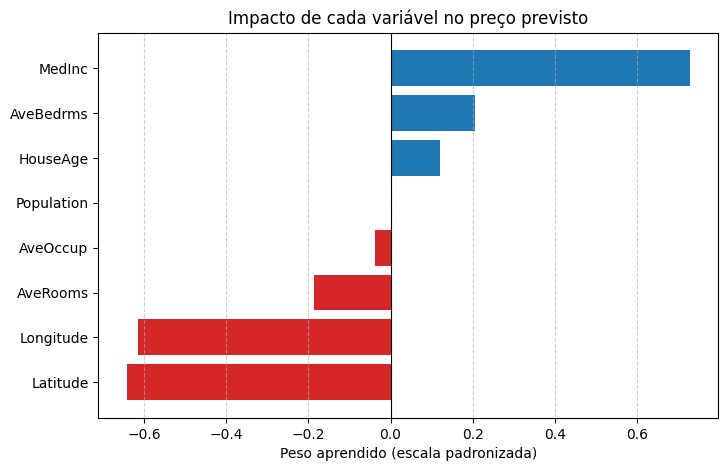

In [42]:
plt.figure(figsize=(8, 5))
cores = ['tab:red' if p < 0 else 'tab:blue' for p in df_pesos['Peso']]
plt.barh(df_pesos['Variável'], df_pesos['Peso'], color=cores)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Peso aprendido (escala padronizada)')
plt.title('Impacto de cada variável no preço previsto')
plt.gca().invert_yaxis()
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.show()

Na análise dos pesos aprendidos pelo modelo, a renda mediana do quarteirão (MedInc) destaca-se como o principal fator que eleva o valor previsto dos imóveis, seguida com menor intensidade pela média de quartos (AveBedrms) e pela idade das casas (HouseAge). Em contrapartida, Latitude e Longitude exercem os maiores impactos negativos, refletindo a desvalorização dos imóveis à medida que se deslocam mais para o norte e para o interior da Califórnia, afastando-se da costa do Pacífico e dos grandes centros do sul.

Sem padronização, as variáveis possuem unidades e escalas muito distintas, fazendo com que os pesos apenas compensem essas diferenças de grandeza em vez de refletirem sua real relevância. Ao aplicar o StandardScaler, todas as entradas ficam na mesma escala (média 0 e desvio padrão 1), permitindo comparar os pesos diretamente pelo impacto de cada desvio padrão no preço previsto.

### 7. Uma conclusão curta: o modelo é bom o suficiente? O que você tentaria para melhorar?

De modo geral, o modelo linear funciona bem como ponto de partida ao reduzir o erro médio (RMSE) no teste de US 116.708,28 (baseline) para US 72.958,56, uma melhora de cerca de 37,5%. Contudo, frente ao preço médio de US 206,7 mil, um erro próximo a US 73 mil ainda é elevado para aplicações práticas de precificação, evidenciando que a relação entre essas variáveis e o valor dos imóveis exige abordagens não-lineares mais sofisticadas.